In [2]:
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(["science", "no-latex"])
import numpy as np
from Influence_Modelling import Network, XsvNetwork, Heuristics
import seaborn as sns

In [3]:
net = XsvNetwork.XsvNetwork("airports")
N = net.get_nx()
deg = set(Heuristics.deg_h(N, 100))
cluster = set(Heuristics.local_clustering_coefficient_h(N, 100))
between = set(Heuristics.betweenness_centrality_h(N, 100))

In [4]:
sets = [deg, cluster, between]
intersections = {}
for i in range(3):
  for j in range(i, 3):
    if i != j:
      intersections[(i, j)] = set.intersection(sets[i], sets[j])

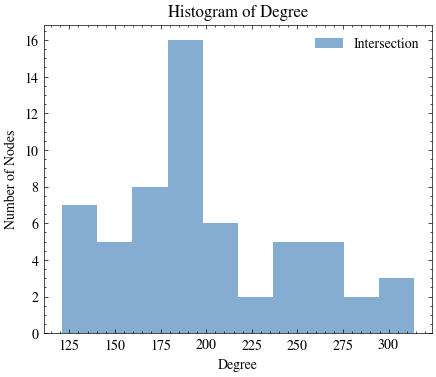

In [5]:
inter = [N.degree(g) for g in list(intersections[(0,2)])]
fig, ax = plt.subplots()
fig.set_size_inches(5,4)
ax.hist(inter, label="Intersection", alpha=0.5)
ax.set_xlabel("Degree")
ax.set_ylabel("Number of Nodes")
ax.set_title("Histogram of Degree")
ax.legend()

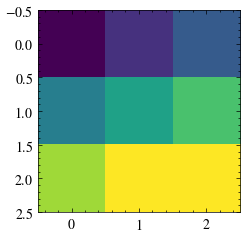

In [6]:
import numpy as np
X=  np.array([
  [1,2,3],
  [4,5,6],
  [7,8,8]
])
plt.imshow(X)

In [7]:
def find_overlaps(methods, size_set, axis, network):
    intersections = {}
    names = []
    for method in methods:
        name = str(method).split(" ")[1]
        names.append(name)
        seeds = set(method(network, size_set))
        intersections[name] = seeds
    abs_matrix = []
    for name in names:
        row = []
        for other_name in names:
            row.append(
                len(
                    list(
                        set.intersection(intersections[name], intersections[other_name])
                    )
                )
            )
        abs_matrix.append(row)
    scaled = np.array(abs_matrix) / size_set
    axis.set_title("Proportion of Selected Seed Size Intersecting (100 Nodes)")
    sns.heatmap(scaled, annot=True, ax=axis, cmap="RdYlGn_r", cbar=False, xticklabels=names, yticklabels=names, mask=np.tril(np.ones_like(scaled, dtype=bool), k=-1))
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0)

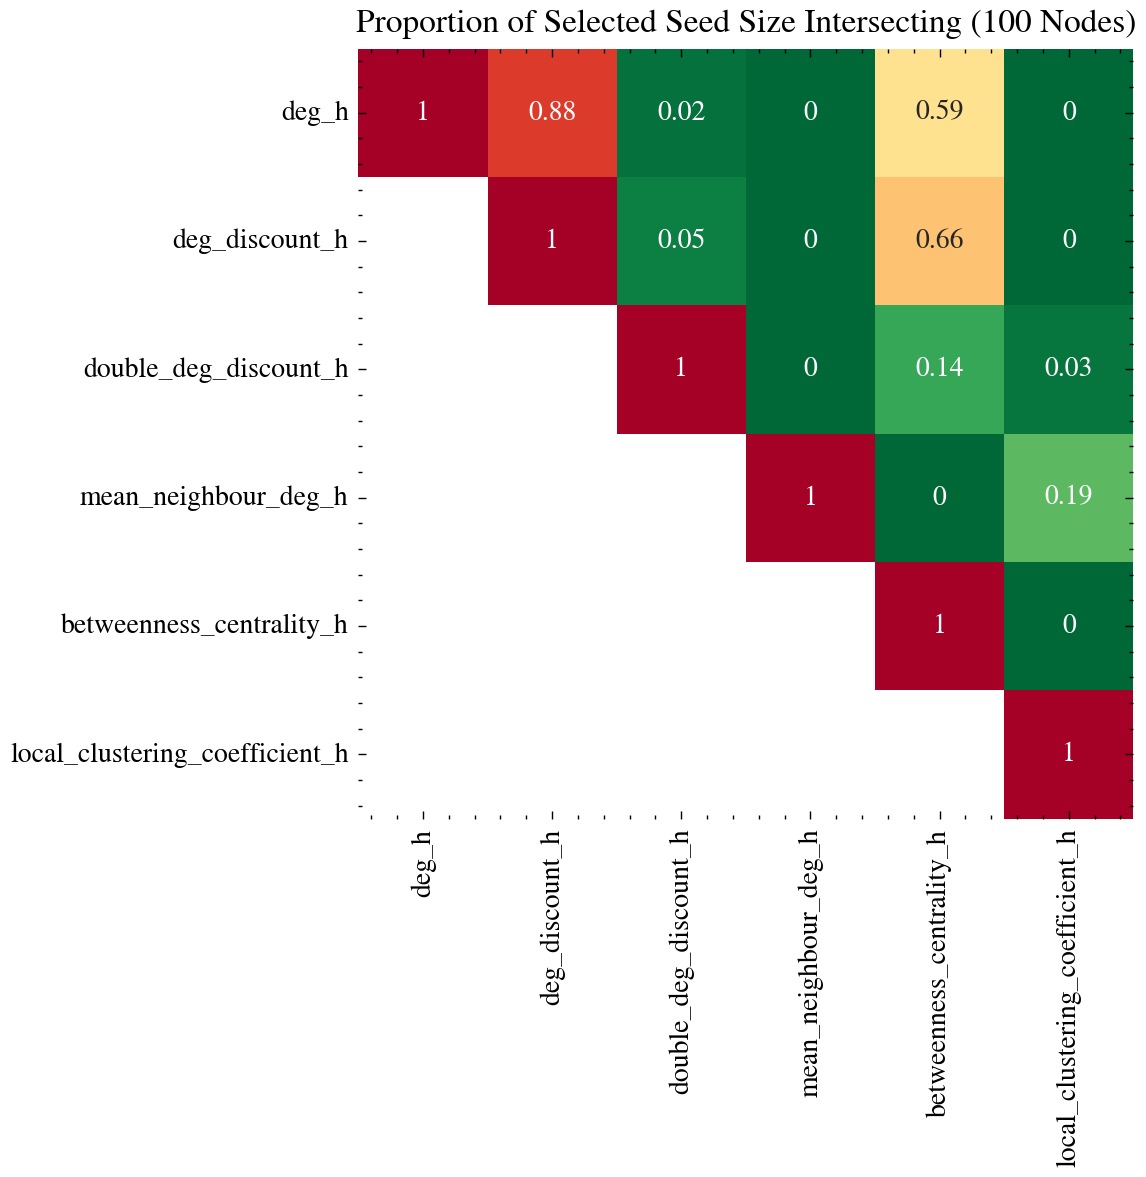

In [8]:
fig, axs = plt.subplots()
fig.set_size_inches(5,5)
fig.set_dpi(200)
find_overlaps([Heuristics.deg_h, Heuristics.deg_discount_h, Heuristics.double_deg_discount_h, Heuristics.mean_neighbour_deg_h, Heuristics.betweenness_centrality_h, Heuristics.local_clustering_coefficient_h], 100, axs, net.get_nx())